All the libraries

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras import layers, models
import tensorflow as tf
import tensorflow_datasets as tfds
from skimage.color import rgb2lab, lab2rgb
import numpy as np
import math
from google.colab import drive
import os
import tensorflow as tf
from tensorflow.keras import layers as KL, models
import torch
import random
from tensorflow.keras import mixed_precision
import numpy as np
import warnings
from skimage.color import lab2rgb, rgb2lab
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers as KL, models


GPU

In [2]:
gpu_avail = torch.cuda.is_available()
print(f"Is the GPU available? {gpu_avail}")

device = torch.device("cuda") if torch.cuda.is_available() else torch.device("cpu")
print(f"Device: {device}")

Is the GPU available? True
Device: cuda


Some parameters

In [3]:
# === CONFIGURATION ===
IMG_SIZE = 128
BATCH_SIZE = 32
# Probabilità di applicare augmentation al campione
AUG_PROB  = 0.0   # DATA AUGMENTATION DISABILITATA
MIN_SCALE = 0.92   # mantieni ≥92% dell'immagine (zoom-in leggero)
BASE = 48

Preprocess image

In [4]:
def preprocess_image(sample):
    """Resize and normalize image"""
    image = tf.image.resize(sample['image'], (IMG_SIZE, IMG_SIZE))
    image = tf.cast(image, tf.float32) / 255.0
    return image

RGB to LAB and Viceversa

Generator for grey

In [5]:
# === DATA GENERATOR ===
class GrayScaleGenerator(tf.keras.utils.Sequence):
    def __init__(self, images, batch_size=BATCH_SIZE, shuffle=True):
        self.images = images.numpy() # Convert to numpy array
        self.batch_size = batch_size
        self.shuffle = shuffle
        self.indices = np.arange(len(images))
        if self.shuffle:
            np.random.shuffle(self.indices)

    def __len__(self):
        return len(self.images) // self.batch_size

    def __getitem__(self, idx):
        batch_indices = self.indices[idx * self.batch_size:(idx + 1) * self.batch_size]
        batch_color = self.images[batch_indices]
        batch_gray = np.mean(batch_color,axis=-1)
        batch_palette = np.mean(batch_color,axis=(1,2)) # batch of color palettes
        return (batch_gray, batch_palette), batch_color

    def on_epoch_end(self):
        if self.shuffle:
            np.random.shuffle(self.indices)

Data Agumentation Utility

In [6]:
# === Oxford Flowers augmentation (solo geometriche, NO blur, NO color jitter) ===
# profilo di default "safe" per fiori 128x128


def _choose_rotation_k(allow_90s: bool):
    """
    allow_90s=True  -> {0,1,2,3}  => 0°, 90°, 180°, 270°
    allow_90s=False -> {0,2}      => 0°, 180°
    """
    if allow_90s:
        return tf.random.uniform([], 0, 4, dtype=tf.int32)
    else:
        return tf.cast(tf.random.uniform([], 0, 2, dtype=tf.int32) * 2, tf.int32)

def _rot90_k(img, k):
    return tf.image.rot90(img, k)

def _random_resized_crop(img, out_size, min_scale=0.92):
    """
    Random crop con scala uniforme in [min_scale, 1.0], poi resize all'output.
    Lavora su RGB [0,1].
    """
    h = tf.shape(img)[0]; w = tf.shape(img)[1]
    scale = tf.random.uniform([], min_scale, 1.0)
    nh = tf.cast(tf.cast(h, tf.float32) * scale, tf.int32)
    nw = tf.cast(tf.cast(w, tf.float32) * scale, tf.int32)
    # ritaglio random (mantieni proporzioni), poi resize all'out_size
    crop = tf.image.random_crop(img, size=tf.stack([nh, nw, 3]))
    crop = tf.image.resize(crop, (out_size, out_size), method="bilinear")
    return crop

def augment_rgb01_np(rgb01, out_size: int, prob: float = AUG_PROB,
                     min_scale: float = MIN_SCALE, allow_90s: bool = True):
    """
    rgb01: np.ndarray (H,W,3) in [0,1]
    Ritorna: np.ndarray (out_size, out_size, 3) in [0,1]
    Augmentazioni: flip LR, rotazione (0/180 o 0/90/180/270), random resized crop.
    Nessun blur, nessun color jitter.
    """
    t = tf.convert_to_tensor(rgb01, dtype=tf.float32)

    if tf.random.uniform([]) < prob:
        # 1) flip orizzontale
        t = tf.image.random_flip_left_right(t)
        # 2) rotazione (configurabile)
        k = _choose_rotation_k(allow_90s)
        t = _rot90_k(t, k)
        # 3) crop/resize moderato
        t = _random_resized_crop(t, out_size, min_scale=min_scale)
    else:
        # solo uniforma la dimensione se necessario (no distorsioni)
        t = tf.image.resize(t, (out_size, out_size), method="bilinear")

    return t.numpy()


Generator for L + palette

Load and splitters extended to use all the dataset

In [7]:
def load_flower_dataset_splits():
    base = "train+validation+test"  # unisci tutto

    ds_train = tfds.load(
        'oxford_flowers102',
        split=f'{base}[:80%]',
        shuffle_files=True,
        read_config=tfds.ReadConfig(shuffle_seed=42)
    )
    ds_val = tfds.load(
        'oxford_flowers102',
        split=f'{base}[80%:90%]',
        shuffle_files=True,
        read_config=tfds.ReadConfig(shuffle_seed=42)
    )
    ds_test = tfds.load(
        'oxford_flowers102',
        split=f'{base}[90%:]',
        shuffle_files=True,
        read_config=tfds.ReadConfig(shuffle_seed=42)
    )

    ds_train = tf.stack(list(ds_train.map(preprocess_image)))
    ds_val   = tf.stack(list(ds_val.map(preprocess_image)))
    ds_test  = tf.stack(list(ds_test.map(preprocess_image)))

     # Stampe utili
    print("[Flowers102 80/10/10]")
    print(f"  train: {ds_train.shape[0]} immagini")
    print(f"  val:   {ds_val.shape[0]} immagini")
    print(f"  test:  {ds_test.shape[0]} immagini")
    print(f"  image shape per sample: {ds_train.shape[1:]}  dtype={ds_train.dtype}")

    return (ds_train, ds_val, ds_test)


TO use the grayscale

In [8]:

train_imgs, val_imgs, test_imgs = load_flower_dataset_splits()

train_rgb = GrayScaleGenerator(train_imgs, batch_size=BATCH_SIZE)
val_rgb = GrayScaleGenerator(val_imgs, batch_size=BATCH_SIZE)
test_rgb = GrayScaleGenerator(test_imgs, batch_size=BATCH_SIZE)



Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/3 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

...

Generating test examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/oxford_flowers102/incomplete.O6QXCM_2.1.1/oxford_flowers102-test.tfrecord*…

Generating validation examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/oxford_flowers102/incomplete.O6QXCM_2.1.1/oxford_flowers102-validation.tfr…

Dataset oxford_flowers102 downloaded and prepared to /root/tensorflow_datasets/oxford_flowers102/2.1.1. Subsequent calls will reuse this data.
[Flowers102 80/10/10]
  train: 6959 immagini
  val:   2655 immagini
  test:  2655 immagini
  image shape per sample: (128, 128, 3)  dtype=<dtype: 'float32'>


To use the L + palette

MODEL - Unet + FiLM

In [20]:
# ---------- FiLM: y = (1 + gamma) * x + beta (compatibile Keras 3) ----------
def film(x, pal, channels, name=None):
    gamma = KL.Dense(channels, activation=None, name=None if name is None else name+"_gamma")(pal)
    beta  = KL.Dense(channels, activation=None, name=None if name is None else name+"_beta")(pal)
    gamma = KL.Reshape((1,1,channels), name=None if name is None else name+"_gamma_rs")(gamma)
    beta  = KL.Reshape((1,1,channels),  name=None if name is None else name+"_beta_rs")(beta)
    scale = KL.Lambda(lambda t: t + 1.0, name=None if name is None else name+"_scale")(gamma)  # 1+gamma
    x = KL.Multiply(name=None if name is None else name+"_mul")([x, scale])
    x = KL.Add(name=None if name is None else name+"_add")([x, beta])
    return x

# ---------- Conv block (due Conv2D piene per capacità) ----------
def conv_block(x, filters, k=3, name=None):
    x = KL.Conv2D(filters, k, padding="same", use_bias=False, name=None if name is None else name+"_conv1")(x)
    x = KL.BatchNormalization(name=None if name is None else name+"_bn1")(x)
    x = KL.Activation("relu", name=None if name is None else name+"_act1")(x)

    x = KL.Conv2D(filters, k, padding="same", use_bias=False, name=None if name is None else name+"_conv2")(x)
    x = KL.BatchNormalization(name=None if name is None else name+"_bn2")(x)
    x = KL.Activation("relu", name=None if name is None else name+"_act2")(x)
    return x

def down_block(x, pal, filters, use_film=True, name=None):
    x = conv_block(x, filters, name=None if name is None else name+"_conv")
    if use_film:
        x = film(x, pal, filters, name=None if name is None else name+"_film")
    skip = x
    x = KL.MaxPooling2D(name=None if name is None else name+"_pool")(x)
    return x, skip

def up_block(x, skip, pal, filters, use_film=True, name=None):
    x = KL.UpSampling2D(name=None if name is None else name+"_up")(x)
    x = KL.Concatenate(name=None if name is None else name+"_cat")([x, skip])
    x = conv_block(x, filters, name=None if name is None else name+"_conv")
    if use_film:
        x = film(x, pal, filters, name=None if name is None else name+"_film")
    return x

# ---------- Palette map (opzionale) ----------
def palette_map(pal, ref, name=None):
    def _tile(args):
        p, r = args
        h = tf.shape(r)[1]; w = tf.shape(r)[2]
        p = tf.reshape(p, (-1,1,1,3))
        return tf.tile(p, [1, h, w, 1])
    return KL.Lambda(_tile, name=name)([pal, ref])

def build_unet_film_rgb(img_size=128, base=40, depth=3, use_film=True, use_palette_map=True):
    """
    depth=3: canali 40→80→160, bottleneck 320, decoder simmetrico.
    Param count ~3.0–3.2M (senza contare BN minime) a seconda della build.
    """
    inp_gray = KL.Input((img_size, img_size, 1), name="gray_input")
    inp_pal  = KL.Input((3,), name="palette_input")

    x0 = inp_gray
    if use_palette_map:
        pmap = palette_map(inp_pal, inp_gray, name="palette_map")
        x0 = KL.Concatenate(name="gray_plus_palette")([inp_gray, pmap])  # (H,W,4)

    # Encoder
    skips = []
    x = x0
    f = base  # 40
    for d in range(depth):           # 3 livelli: 40, 80, 160
        x, skip = down_block(x, inp_pal, f, use_film=use_film, name=f"enc{d+1}")
        skips.append(skip)
        f *= 2                        # 40→80→160

    # Bottleneck (320)
    x = conv_block(x, f, name="bottleneck_conv")
    if use_film:
        x = film(x, inp_pal, f, name="bottleneck_film")

    # Decoder
    for d in reversed(range(depth)):  # 160, 80, 40
        f //= 2
        x = up_block(x, skips[d], inp_pal, f, use_film=use_film, name=f"dec{depth-d}")

    out = KL.Conv2D(3, 1, activation="sigmoid", name="rgb_out")(x)
    return models.Model([inp_gray, inp_pal], out, name="UNet_FiLM_RGB_3M")

In [22]:
tf.keras.backend.clear_session()
model = build_unet_film_rgb(img_size=IMG_SIZE, base=40, depth=3, use_film=True, use_palette_map=True)
model.summary()
print("Params:", model.count_params())

Model: "UNet_FiLM_RGB_3M"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ gray_input          │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ palette_input       │ (None, 3)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ palette_map         │ (None, 128, 128,  │          0 │ palette_input[0]… │
│ (Lambda)            │ 3)                │            │ gray_input[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gray_plus_palette   │ (None, 128, 128,  │          0 │ gray_input[0][0], │
│ (Concatenate)       │ 4)                │            │ palette_map[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc1_conv_conv1     │ (None, 128, 128,  │      1,440 │ gray_plus_palett… │
│ (Conv2D)            │ 40)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc1_conv_bn1       │ (None, 128, 128,  │        160 │ enc1_conv_conv1[… │
│ (BatchNormalizatio… │ 40)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc1_conv_act1      │ (None, 128, 128,  │          0 │ enc1_conv_bn1[0]… │
│ (Activation)        │ 40)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc1_conv_conv2     │ (None, 128, 128,  │     14,400 │ enc1_conv_act1[0… │
│ (Conv2D)            │ 40)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc1_film_gamma     │ (None, 40)        │        160 │ palette_input[0]… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc1_conv_bn2       │ (None, 128, 128,  │        160 │ enc1_conv_conv2[… │
│ (BatchNormalizatio… │ 40)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc1_film_gamma_rs  │ (None, 1, 1, 40)  │          0 │ enc1_film_gamma[… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc1_conv_act2      │ (None, 128, 128,  │          0 │ enc1_conv_bn2[0]… │
│ (Activation)        │ 40)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc1_film_scale     │ (None, 1, 1, 40)  │          0 │ enc1_film_gamma_… │
│ (Lambda)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc1_film_beta      │ (None, 40)        │        160 │ palette_input[0]… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc1_film_mul       │ (None, 128, 128,  │          0 │ enc1_conv_act2[0… │
│ (Multiply)          │ 40)               │            │ enc1_film_scale[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc1_film_beta_rs   │ (None, 1, 1, 40)  │          0 │ enc1_film_beta[0… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc1_film_add (Add) │ (None, 128, 128,  │          0 │ enc1_film_mul[0]

 Total params: 3,054,043 (11.65 MB)

 Trainable params: 3,050,523 (11.64 MB)

 Non-trainable params: 3,520 (13.75 KB)

Params: 3054043


Loss function - MSA + (very small) TV

In [45]:
# ===============================
# LOSS FUNCTIONS (per RGB output)
# ===============================

def mae_tv_loss(lambda_tv=1e-4):
    """
    MAE + Total Variation sul pred RGB.
    """
    def loss(y_true, y_pred):
        mae = tf.reduce_mean(tf.abs(y_pred - y_true))
        tv  = tf.reduce_mean(tf.image.total_variation(y_pred))
        return mae + lambda_tv * tv
    return loss

def mse_loss():
    """
    MSE puro sul pred RGB.
    """
    mse = tf.keras.losses.MeanSquaredError(reduction=tf.keras.losses.Reduction.SUM_OVER_BATCH_SIZE)
    def loss(y_true, y_pred):
        return mse(y_true, y_pred)
    return loss

def mae_mse_loss(alpha=0.5, beta=0.5):
    """
    Combinazione di MAE e MSE.
    alpha e beta pesano le due componenti (default 50/50).
    """
    mae = tf.keras.losses.MeanAbsoluteError(reduction=tf.keras.losses.Reduction.SUM_OVER_BATCH_SIZE)
    mse = tf.keras.losses.MeanSquaredError(reduction=tf.keras.losses.Reduction.SUM_OVER_BATCH_SIZE)
    def loss(y_true, y_pred):
        return alpha * mae(y_true, y_pred) + beta * mse(y_true, y_pred)
    return loss

def channelwise_crossentropy_loss(eps=1e-8):
    """
    Interpreta ciascun canale (R,G,B) come distribuzione sui pixel (somma=1).
    CE = - sum_{c in {R,G,B}} sum_{h,w}  P_true[c,h,w] * log P_pred[c,h,w]
    Ritorna la media su batch (SUM_OVER_BATCH_SIZE equivalente).
    """
    def loss(y_true, y_pred):
        # Clip per evitare log(0) e divisioni instabili
        y_true_clipped = tf.clip_by_value(y_true, 0.0, 1.0)
        y_pred_clipped = tf.clip_by_value(y_pred, eps, 1.0)

        # Normalizza per canale su HxW: somma per immagine e canale = 1
        # shape: (B,1,1,3)
        sum_true = tf.reduce_sum(y_true_clipped, axis=[1,2], keepdims=True) + eps
        sum_pred = tf.reduce_sum(y_pred_clipped, axis=[1,2], keepdims=True) + eps
        P_true = y_true_clipped / sum_true
        P_pred = y_pred_clipped / sum_pred

        # Cross-entropy per canale: somma su HxW
        # ce_per_channel: (B,3)
        ce_per_channel = -tf.reduce_sum(P_true * tf.math.log(P_pred + eps), axis=[1,2])

        # media sui 3 canali, poi media sul batch
        ce_per_image = tf.reduce_mean(ce_per_channel, axis=-1)   # (B,)
        return tf.reduce_mean(ce_per_image)
    return loss

def channelwise_ce_plus_mse(alpha=0.5, eps=1e-8):
    """
    alpha * CE_channelwise + (1-alpha) * MSE
    """
    mse = tf.keras.losses.MeanSquaredError(reduction=tf.keras.losses.Reduction.SUM_OVER_BATCH_SIZE)
    ce = channelwise_crossentropy_loss(eps=eps)
    def loss(y_true, y_pred):
        return alpha * ce(y_true, y_pred) + (1.0 - alpha) * mse(y_true, y_pred)
    return loss


Code to test the model:

In [24]:
def baseline(gray,palette):
  m = np.mean(gray, axis=(1,2))
  red = gray*(palette[:,0]/m)[:, np.newaxis, np.newaxis]
  green = gray*(palette[:,1]/m)[:, np.newaxis, np.newaxis]
  blue = gray*(palette[:,2]/m)[:, np.newaxis, np.newaxis]
  return np.stack([red,green,blue],axis=-1)


Code to print the history of training:

In [25]:
def plot_train_val_loss(history, title="Training vs Validation Loss"):
    """
    Disegna il grafico di training loss e validation loss da un oggetto History di Keras.
    """
    plt.figure(figsize=(8,5))
    plt.plot(history.history['loss'], label='Train Loss')
    if 'val_loss' in history.history:
        plt.plot(history.history['val_loss'], label='Val Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.title(title)
    plt.legend()
    plt.grid(True)
    plt.show()

Google drive connectivity

In [26]:
# 1) Monta Google Drive
drive.mount('/content/drive')

# 2) Scegli una cartella su Drive dove salvare i pesi
SAVE_DIR = '/content/drive/MyDrive/Colorizer'   # cambia nome/cartella se vuoi
os.makedirs(SAVE_DIR, exist_ok=True)

# 3) Path per il checkpoint
CKPT_PATH_1 = os.path.join(SAVE_DIR, 'RGB_best_colorizer_1.weights.h5')
CKPT_PATH_2 = os.path.join(SAVE_DIR, 'RGB_best_colorizer_2.weights.h5')
CKPT_PATH_3 = os.path.join(SAVE_DIR, 'RGB_best_colorizer_3.weights.h5')

Mounted at /content/drive


Compile and training

In [27]:

model.compile(
    optimizer=tf.keras.optimizers.Adam(3e-4),
    loss=mae_mse_loss(alpha=0.5, beta=0.5),   # combinazione MAE+MSE
    metrics=[tf.keras.metrics.MeanAbsoluteError(name='mae'),
             tf.keras.metrics.MeanSquaredError(name='mse')]
)


In [28]:
callbacks = [
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',    # MINIMIZZIAMO la loss
        patience=3,
        factor=0.5,
        min_lr=1e-6,
        verbose=1,
        mode='min'
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=8,
        restore_best_weights=True,
        verbose=1,
        mode='min'
    ),
    tf.keras.callbacks.ModelCheckpoint(
        filepath=CKPT_PATH_1,
        monitor='val_loss',
        save_best_only=True,
        save_weights_only=True,
        mode='min',
        verbose=1
    )
]



NOTE: Il pesi ottimali sono stati ottenuti eseguendo diverse volte l'allenamento/codice sottostante. Questo avviene perchè ricominciando l'allenamento da zero riesce a sbloccare il training quando si "siede" su un minimo poco generalizzante. Questo processo è chiamato warm restart.

In [30]:
  history1 = model.fit(
    train_rgb,
    validation_data=val_rgb,
    epochs=200,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/200
217/217 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - loss: 0.0277 - mae: 0.0500 - mse: 0.0053
Epoch 1: val_loss improved from 0.02771 to 0.02631, saving model to /content/drive/MyDrive/Colorizer/RGB_best_colorizer_1.weights.h5
217/217 ━━━━━━━━━━━━━━━━━━━━ 11s 49ms/step - loss: 0.0277 - mae: 0.0500 - mse: 0.0053 - val_loss: 0.0263 - val_mae: 0.0476 - val_mse: 0.0050 - learning_rate: 1.5000e-04
Epoch 2/200
217/217 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - loss: 0.0274 - mae: 0.0495 - mse: 0.0052
Epoch 2: val_loss did not improve from 0.02631
217/217 ━━━━━━━━━━━━━━━━━━━━ 9s 43ms/step - loss: 0.0274 - mae: 0.0495 - mse: 0.0052 - val_loss: 0.0265 - val_mae: 0.0479 - val_mse: 0.0050 - learning_rate: 1.5000e-04
Epoch 3/200
217/217 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - loss: 0.0273 - mae: 0.0493 - mse: 0.0052
Epoch 3: val_loss improved from 0.02631 to 0.02568, saving model to /content/drive/MyDrive/Colorizer/RGB_best_colorizer_1.weights.h5
217/217 ━━━━━━━━━━━━━━━━━━━━ 11s 49ms/step - loss: 0.0273 -

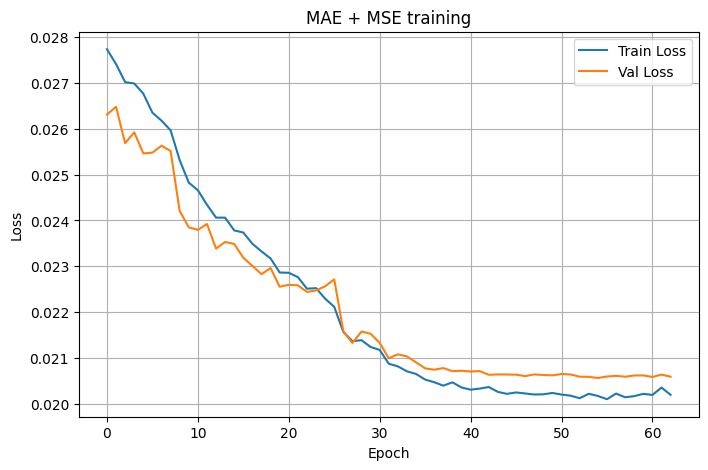

In [32]:
plot_train_val_loss(history1, title="MAE + MSE training")

TO load an old model pretrained

In [33]:
model_snap_1 = build_unet_film_rgb(img_size=IMG_SIZE, base=40, depth=3, use_film=True, use_palette_map=True)
model_snap_1.load_weights(CKPT_PATH_1)

See the results of the model

In [42]:
import numpy as np
import tensorflow as tf
import sys, time

def test_model(model, test_gen, eps=1e-12, max_batches=None, progress_every=10):
    """
    Replica esattamente lo stile del prof (per-canale, media su N*3).
    Iterazione finita: usa range(len(test_gen)).
    Stampa nell'ordine richiesto + riga vuota + media/std ratio.
    """
    mse_model_list, mse_base_list = [], []
    n_images = 0

    n_batches = len(test_gen)
    if max_batches is not None:
        n_batches = min(n_batches, int(max_batches))

    t0 = time.time()
    for i in range(n_batches):
        (x_gray, x_pal), y_true = test_gen[i]

        if x_gray.shape[0] == 0:
            continue

        # forward diretto
        y_pred = model([x_gray, x_pal], training=False).numpy()
        y_base = baseline(x_gray, x_pal)

        # MSE per-canale: media su H,W
        m_mse = np.mean((y_pred - y_true) ** 2, axis=(1, 2))  # (B,3)
        b_mse = np.mean((y_base - y_true) ** 2, axis=(1, 2))  # (B,3)

        mse_model_list.append(m_mse)
        mse_base_list.append(b_mse)
        n_images += x_gray.shape[0]

        if progress_every and ((i + 1) % progress_every == 0 or (i + 1) == n_batches):
            elapsed = time.time() - t0
            sys.stdout.write(f"\rTest batch {i+1}/{n_batches} - elapsed {elapsed:.1f}s")
            sys.stdout.flush()

    if n_images == 0:
        raise RuntimeError("Nessuna immagine valida nel test set. Controlla il generator (__len__/__getitem__).")

    mse_model_all = np.concatenate(mse_model_list, axis=0)
    mse_base_all  = np.concatenate(mse_base_list,  axis=0)

    mse_model_mean = mse_model_all.mean()
    mse_base_mean  = mse_base_all.mean()
    mse_model_std  = mse_model_all.std(ddof=1)
    mse_base_std   = mse_base_all.std(ddof=1)

    ratios = mse_model_all / (mse_base_all + eps)
    ratio_mean = ratios.mean()
    ratio_std  = ratios.std(ddof=1)

    print()  # newline dopo la progress bar

    # Stampa con etichette
    print(f"MSE medio modello   : {mse_model_mean:.6f}")
    print(f"MSE medio baseline  : {mse_base_mean:.6f}")
    print(f"STD MSE modello     : {mse_model_std:.6f}")
    print(f"STD MSE baseline    : {mse_base_std:.6f}")
    print(f"Numero immagini     : {n_images}")
    print()
    print(f"Media ratio (MSE_model/MSE_base) : {ratio_mean:.6f}")
    print(f"STD ratio                        : {ratio_std:.6f}")

    return {
        "mse_model_all": mse_model_all,
        "mse_base_all":  mse_base_all,
        "ratios_all":    ratios
    }


In [43]:
results = test_model(model, test_rgb)  # completo


Test batch 82/82 - elapsed 12.0s
MSE medio modello   : 0.003286
MSE medio baseline  : 0.009567
STD MSE modello     : 0.003726
STD MSE baseline    : 0.010597
Numero immagini     : 2624

Media ratio (MSE_model/MSE_base) : 0.522439
STD ratio                        : 0.515194


Proceed with the second training of the same model using huber

In [47]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(3e-4),
    loss=channelwise_ce_plus_mse(),   # combinazione MAE+MSE
    metrics=[tf.keras.metrics.MeanAbsoluteError(name='mae'),
             tf.keras.metrics.MeanSquaredError(name='mse')]
)

callbacks = [
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        patience=3,
        factor=0.5,
        min_lr=1e-6,
        verbose=1,
        mode='min'
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=8,
        restore_best_weights=True,
        verbose=1,
        mode='min'
    ),
    tf.keras.callbacks.ModelCheckpoint(
        filepath=CKPT_PATH_2,
        monitor='val_loss',
        save_best_only=True,
        save_weights_only=True,
        mode='min',
        verbose=1
    )
]


# --- Train Fase 2 ---
history2 = model.fit(
    train_rgb,
    validation_data=val_rgb,
    epochs=100,
    callbacks=callbacks,
    verbose=1
)


Epoch 1/100
217/217 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - loss: 4.7272 - mae: 0.0455 - mse: 0.0043
Epoch 1: val_loss improved from inf to 4.72917, saving model to /content/drive/MyDrive/Colorizer/RGB_best_colorizer_2.weights.h5
217/217 ━━━━━━━━━━━━━━━━━━━━ 31s 56ms/step - loss: 4.7272 - mae: 0.0455 - mse: 0.0043 - val_loss: 4.7292 - val_mae: 0.0476 - val_mse: 0.0049 - learning_rate: 3.0000e-04
Epoch 2/100
217/217 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - loss: 4.7251 - mae: 0.0449 - mse: 0.0042
Epoch 2: val_loss improved from 4.72917 to 4.72810, saving model to /content/drive/MyDrive/Colorizer/RGB_best_colorizer_2.weights.h5
217/217 ━━━━━━━━━━━━━━━━━━━━ 10s 45ms/step - loss: 4.7251 - mae: 0.0449 - mse: 0.0042 - val_loss: 4.7281 - val_mae: 0.0461 - val_mse: 0.0045 - learning_rate: 3.0000e-04
Epoch 3/100
217/217 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - loss: 4.7267 - mae: 0.0460 - mse: 0.0044
Epoch 3: val_loss did not improve from 4.72810
217/217 ━━━━━━━━━━━━━━━━━━━━ 9s 43ms/step - loss: 4.7267 - mae

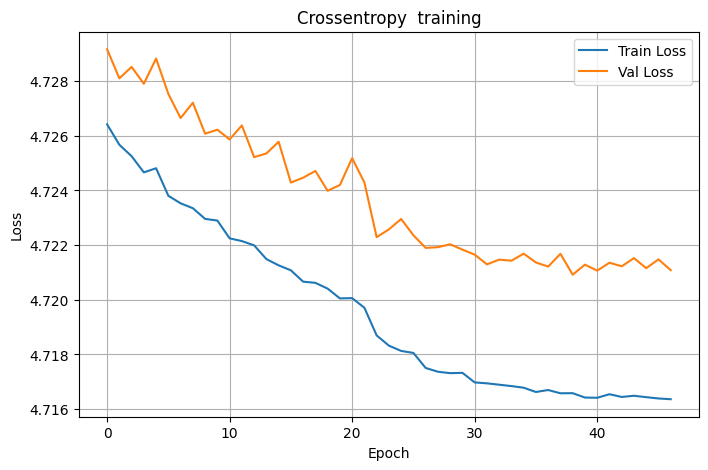

In [48]:
plot_train_val_loss(history2, title="Crossentropy  training")

Rest:

Creating model_snap_2 (equal to model)

In [52]:
model_snap_2 = build_unet_film_rgb(img_size=IMG_SIZE, base=40, depth=3, use_film=True, use_palette_map=True)
model_snap_2.load_weights(CKPT_PATH_2)

See the results:

In [49]:
results = test_model(model, test_rgb)  # completo


Test batch 82/82 - elapsed 12.1s
MSE medio modello   : 0.002798
MSE medio baseline  : 0.009567
STD MSE modello     : 0.003354
STD MSE baseline    : 0.010597
Numero immagini     : 2624

Media ratio (MSE_model/MSE_base) : 0.482069
STD ratio                        : 0.547473


Showing a random example

In [55]:
import numpy as np
import matplotlib.pyplot as plt

def show_random_sample_rgb(test_gen, model_snap_1, model_snap_3=None, seed=None, clip_rgb=True):
    """
    Mostra: grayscale, baseline, model_snap_1, (facoltativo) model_snap_3, ground truth
    - test_gen: GrayScaleGenerator -> ((gray, palette), rgb_true)
    - model_snap_*: modelli che predicono RGB in [0,1]
    """
    rng = np.random.default_rng(seed)

    # 1) scegli batch e indice random
    bidx = rng.integers(low=0, high=len(test_gen))
    (gray_batch, palette_batch), rgb_true_batch = test_gen[bidx]  # gray:(B,?, ?,1), palette:(B,3), rgb_true:(B,H,W,3)
    B = gray_batch.shape[0]
    iidx = rng.integers(low=0, high=B)

    # 2) estrai sample
    gray     = gray_batch[iidx:iidx+1, ...]       # (1,*,*,1) o simile
    palette  = palette_batch[iidx:iidx+1, ...]    # (1,3)
    rgb_true = rgb_true_batch[iidx:iidx+1, ...]   # (1,H,W,3)

    # 3) predizioni modello/i (RGB)
    rgb_pred1 = model_snap_1([gray, palette], training=False)
    rgb_pred3 = model_snap_3([gray, palette], training=False) if model_snap_3 is not None else None

    # 4) baseline (RGB)
    rgb_base = baseline(gray, palette)  # (1,H,W,3)

    # 5) clipping opzionale
    if clip_rgb:
        rgb_true  = np.clip(np.array(rgb_true),  0.0, 1.0)
        rgb_pred1 = np.clip(np.array(rgb_pred1), 0.0, 1.0)
        rgb_base  = np.clip(np.array(rgb_base),  0.0, 1.0)
        if rgb_pred3 is not None:
            rgb_pred3 = np.clip(np.array(rgb_pred3), 0.0, 1.0)
    else:
        rgb_true  = np.array(rgb_true)
        rgb_pred1 = np.array(rgb_pred1)
        rgb_base  = np.array(rgb_base)
        if rgb_pred3 is not None:
            rgb_pred3 = np.array(rgb_pred3)

    # 6) squeeze & shape fix
    H, W = rgb_true.shape[1:3]
    # gray -> 2D (H,W) robusto:
    g = np.array(gray[0, ...])
    g = np.squeeze(g)               # rimuove singleton
    if g.ndim == 0:
        g = np.full((H, W), float(g))
    elif g.ndim == 1:
        # se è (H,) o (W,), rimappa a (H,W) usando shape della GT
        if g.shape[0] == H:
            g = g.reshape(H, 1).repeat(W, axis=1)
        elif g.shape[0] == W:
            g = g.reshape(1, W).repeat(H, axis=0)
        else:
            # fallback: ridimensiona
            g = g.reshape(H, W)
    elif g.ndim == 3 and g.shape[-1] == 1:
        g = g[..., 0]               # (H,W,1) -> (H,W)
    # rgb:
    rgb_t = rgb_true[0]
    rgb_p1 = rgb_pred1[0]
    rgb_b  = rgb_base[0]
    rgb_p3 = rgb_pred3[0] if rgb_pred3 is not None else None

    # 7) plot (ordine richiesto)
    ncols = 5 if rgb_p3 is not None else 4
    plt.figure(figsize=(3.4*ncols, 3.2))
    plt.subplot(1, ncols, 1); plt.imshow(g, cmap='gray'); plt.title('Grayscale');    plt.axis('off')
    plt.subplot(1, ncols, 2); plt.imshow(rgb_b);           plt.title('Baseline');     plt.axis('off')
    plt.subplot(1, ncols, 3); plt.imshow(rgb_p1);          plt.title('Model snap 1'); plt.axis('off')
    if rgb_p3 is not None:
        plt.subplot(1, ncols, 4); plt.imshow(rgb_p3);      plt.title('Model snap 3'); plt.axis('off')
        plt.subplot(1, ncols, 5); plt.imshow(rgb_t);       plt.title('Ground Truth');  plt.axis('off')
    else:
        plt.subplot(1, ncols, 4); plt.imshow(rgb_t);       plt.title('Ground Truth');  plt.axis('off')
    plt.tight_layout()
    plt.show()


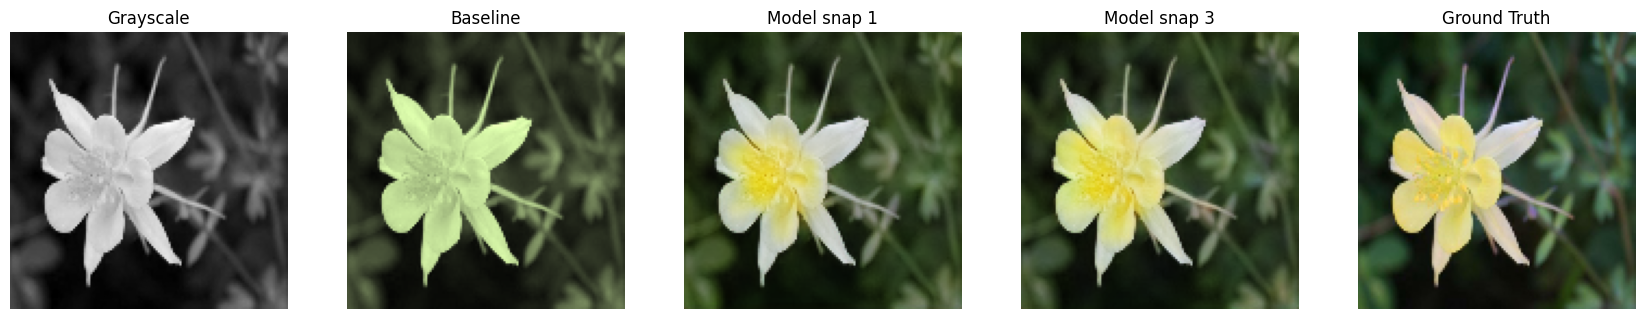

In [123]:
show_random_sample_rgb(test_rgb, model_snap_1, model_snap_2, seed = 6)